[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/HybridQCNN_ExplainableMalware_Ciaramella2023.ipynb)

# Hybrid quanvolutional CNN for explainable malware-family detection: Ciaramella et al. (2023) step by step

**Paper.** G. Ciaramella, F. Martinelli, F. Mercaldo, A. Santone, *Exploring Quantum Machine Learning for Explainable Malware Detection*, 2023 International Joint Conference on Neural Networks (IJCNN), IEEE, 2023. DOI: [10.1109/IJCNN54540.2023.10191964](https://doi.org/10.1109/IJCNN54540.2023.10191964).

**What this notebook does.** The paper turns Windows malware files into small grayscale pictures, classifies them into 25 malware families plus "trusted" software with a *hybrid quantum-classical* convolutional network (a quanvolutional layer followed by ordinary Keras layers), compares it with the old LeNet network, and then uses two *class activation mapping* algorithms (Grad-CAM++ and Score-CAM) to show which parts of the picture drive each decision. The notebook rebuilds each step:

1. downloads the **real MaleVis dataset** (14,226 images, 25 malware families + one trusted class) and turns it into 25x25 / 32x32 grayscale images, exactly as the paper describes;
2. explores the data (class bar chart, sample images, 2-D projections of real images coloured by family);
3. builds the quanvolutional layer as a real 4-qubit circuit (simulated exactly, differentiably, with TensorFlow), checks it against a Qiskit statevector simulation, and draws the circuit;
4. trains the hybrid network, a classical network with the identical architecture, the paper's LeNet baseline, and Random Forest / SVC on the same 25x25 pixels;
5. re-draws the paper's accuracy/loss curves, confusion matrix, per-family table and Grad-CAM++ / Score-CAM heat-maps, and tests the explanations quantitatively (agreement between the two methods, deletion test, comparison with permutation importance on the quantum model and on the classical models);
6. prints the paper's numbers next to ours with a verdict per claim.

**How to run.** Google Colab, CPU runtime is enough: *Runtime -> Run all*. `FAST_MODE = True` (default in the configuration cell) uses a class-balanced subset of 100 images per class and finishes in roughly 20 to 40 minutes on a CPU runtime (the executed copy stored here took 38 minutes on a heavily shared CPU; the download of 2,600 images is about 2.5 minutes); `FAST_MODE = False` follows the paper's data volume and training budgets (see the configuration cell for the runtime it needs). The dataset is public and needs no token; it is read from a public Kaggle mirror with plain HTTP range requests, so no Kaggle account is needed either.

**What you get at the end.** Per-claim verdicts ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for the paper's accuracy, precision, recall, F-measure, AUC, the hybrid-vs-LeNet comparison, the hard and easy families, and the explainability claim.

**Which run is stored here.** The saved outputs come from one complete `FAST_MODE = True` run (2,600 images, one training setting of 5 epochs, one seed). The full run (14,226 images, four settings, 70 hybrid epochs, 11,374 training images per epoch) was estimated at well over 90 minutes on the shared CPU used for validation, so it was not executed; its budgets are documented in the configuration cell. **All numbers below therefore come from the reduced run and must not be compared one-to-one with the paper's full-data numbers.**

## The paper in one page

* **Problem.** Classify a Windows executable into one of 25 malware families or "trusted", from a grayscale picture of its bytes (`bin2png`, Sultanik). Explain *where in the picture* the model looks.
* **Data.** MaleVis (Hacettepe University with Comodo): 14,226 images, 25 malware families (about 500 each: Adposhel, Agent, Allaple, Amonetize, Androm, Autorun, BrowseFox, Dinwod, Elex, Expiro, Fasong, HackKMS, Hlux, Injector, InstallCore, MultiPlug, Neoreklami, Neshta, Regrun, Sality, Snarasite, Stantinko, VBA, VBKrypt, Vilse/Vilsel) + 1,832 trusted samples. Split 80/10/10 = 11,374 / 1,413 / 1,439 images.
* **Model.** Listing 1: `QConv(filter_size=2, depth=8, relu)` -> `Conv2D(16, 2x2, relu)` -> `Flatten` -> `Dense(32, relu)` -> `Dense(26, softmax)` on 25x25x1 input. Learning rate 0.001; (epochs, batch) settings in Table I. The quantum layer was *simulated* (no quantum computer).
* **Baseline.** LeNet on 32x32x1 pictures, same data and similar hyper-parameters.
* **Explainability.** Grad-CAM++ and Score-CAM heat-maps of the best hybrid model (yellow = important, blue = ignored).
* **Claims.** Best hybrid run: accuracy 0.850, precision 0.892, recall 0.830, F-measure 0.860, AUC 0.974 (Table II); LeNet is worse than even the worst hybrid run (best LeNet accuracy 0.698); training the hybrid model takes much longer than LeNet; more epochs or bigger batches *lowered* the hybrid accuracy; the Sality family is hard (accuracy 0.960, precision 0.428, recall 0.235, F 0.303, AUC 0.611) and so are trusted samples; Adposhel, Fasong, HackKMS, Regrun, Snarasite and VBA are classified perfectly; both CAM methods highlight the same image areas.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | MaleVis, 14,226 images, 25 families + trusted | Same 14,226 images (official MaleVis `train`+`val` folders pooled; read from the public Kaggle mirror `sohamkumar1703/malevis-dataset`, the official site only offers a registration form). The class "Other" is the paper's trusted class; "Vilsel" is the paper's "Vilse". |
| Image preparation | Grayscale, 25x25 (hybrid) and 32x32 (LeNet) | 300x300 RGB PNG -> grayscale -> Lanczos resize to 25x25 and 32x32, pixels scaled to [0, 1] (`# CHOICE`). |
| Split | 80/10/10 = 11,374 / 1,413 / 1,439 | Pooled, stratified, same counts in the full run (`FAST_MODE=False`); 80/10/10 of the subset in the fast run. |
| Quantum layer | `QConv(filter_size=2, depth=8)`, implementation not given | `# CHOICE:` each 2x2 patch (stride 1) is encoded on 4 qubits by `RY(pi*pixel)`, passed through a trainable circuit of 2 layers [RY on every qubit + CNOT ring], and the output is the expectation value of Z on qubit 0; `depth=8` is read as 8 output channels (8 independent trainable circuits, 64 quantum parameters). Exact statevector simulation implemented in TensorFlow so that it is trainable by back-propagation; verified against Qiskit. |
| Rest of the network | Listing 1 | Identical (Conv2D 16 / 2x2 -> Flatten -> Dense 32 -> Dense 26 softmax). |
| Optimiser / loss | learning rate 0.001, nothing else | `# CHOICE:` Adam, sparse categorical cross-entropy. |
| (epochs, batch) | Table I (garbled in the PDF text) | `# CHOICE:` read as (10, 32), (30, 32), (10, 64), (20, 64) in the order of Table II. The fast run trains only (5, 32). |
| Metric averaging | not stated | `# CHOICE:` macro-average over the 26 classes; AUC = macro one-vs-rest. |
| LeNet | LeNet, 32x32x1 | Classic LeNet-5 (tanh, average pooling), Adam 0.001, same budgets. |
| Grad-CAM++ / Score-CAM | named, last conv layer | Own implementations (no extra package), target layer = the `Conv2D(16)` layer, viridis colours (yellow high, blue low). |
| Explainability on classical models | not in the paper | Added: block-wise permutation importance on the hybrid model, the classical twin, Random Forest and SVC (`shap` is not used so that nothing extra has to be installed). |
| Training time | Table I (hours to days on a Xeon) | Reported for our simulator; only the *ratio* to LeNet is comparable. |

In [1]:
# Installs pinned to the versions this notebook was tested with.  Colab already ships tensorflow/keras,
# numpy, pandas, scikit-learn, matplotlib and Pillow.  Qiskit is only used to check and draw the quantum circuit.
import importlib.util, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("pylatexenc") is None:
    !pip -q install "qiskit==2.5.2" pylatexenc
    # If Colab asks for a runtime restart after this cell, restart and run again from the top.

In [2]:
# ------------------------------ configuration (every tunable constant) ------------------------------
SEED = 42
FAST_MODE = True              # True: ~100 images per class, one training setting, ~15-25 min (download dominates).
                              # False: all 14,226 images and the paper's four (epochs, batch) settings (see below).
DATA_DIR = "malevis_data"     # small cache (25x25 and 32x32 arrays only, ~25 MB); the 3 GB archive is never stored
LOCAL_ZIP = ""                # optional: path of your own copy of the MaleVis zip (official download or the Kaggle zip)
IBM_TOKEN = ""                # not needed: the quantum layer is simulated, as in the paper

IMG_Q, IMG_L = 25, 32         # image sizes for the hybrid model and for LeNet (paper, Table I)
N_FILTERS = 8                 # "depth=8" of QConv
LEARNING_RATE = 1e-3          # paper
DOWNLOAD_THREADS = 10
TF_THREADS = 4                # CPU threads used by TensorFlow (shared machines: keep small)

if FAST_MODE:
    N_PER_CLASS = 100                      # class-balanced subset (26 x 100 = 2,600 images)
    CONFIGS = [(5, 32)]                    # (epochs, batch size)
    N_CAM, PI_N, PI_REPEATS = 30, 300, 2   # images explained / images used for permutation importance / repeats
    RF_TREES = 200
    MAX_TRAIN_MIN = 20
else:
    N_PER_CLASS = None                     # all images
    CONFIGS = [(10, 32), (30, 32), (10, 64), (20, 64)]   # paper Table I/II order (see the table above)
    N_CAM, PI_N, PI_REPEATS = 150, 600, 3
    RF_TREES = 300
    MAX_TRAIN_MIN = 75                     # settings not started before this wall-clock budget are skipped and reported
# Full-run budget: one epoch of the hybrid model on 11,374 images takes about 0.8 min on a 4-thread CPU, so the four
# settings (70 epochs) need about 1 h, plus ~20 min to download the images once and ~15 min for LeNet/baselines/explanations.
PAPER_SPLIT = (1439, 1413)    # test and validation sizes of the paper (11,374 train)

In [3]:
import os, io, re, sys, time, json, math, pickle, struct, zlib, random, threading, warnings
from concurrent.futures import ThreadPoolExecutor
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf, keras
from keras import layers
import sklearn, qiskit
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix)
from scipy.stats import spearmanr, pearsonr
warnings.filterwarnings("ignore")

random.seed(SEED); np.random.seed(SEED); rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
try:
    tf.config.threading.set_intra_op_parallelism_threads(TF_THREADS); tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
os.makedirs(DATA_DIR, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("tensorflow", tf.__version__, "| keras", keras.__version__, "| backend", keras.backend.backend(), "| qiskit", qiskit.__version__)
assert keras.backend.backend() == "tensorflow", "this notebook needs the TensorFlow backend of Keras"

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
tensorflow 2.21.0 | keras 3.15.1 | backend tensorflow | qiskit 2.5.2


## 1. Data: the real MaleVis dataset

MaleVis is the dataset of the paper. Its official page (Hacettepe University) hands the files out through a registration form, but the identical official archive (`malevis_train_val_300x300`, 9,100 training + 5,126 validation images, 26 class folders) is also on Kaggle as `sohamkumar1703/malevis-dataset` and can be fetched without logging in. It is a 3.1 GB zip, so the next cell reads *only the members it needs* with HTTP range requests (the zip's directory is read first, then each PNG individually), shrinks every picture to 25x25 and 32x32 grayscale and keeps only these small arrays in `DATA_DIR`. If you prefer the official files, download them yourself and set `LOCAL_ZIP` in the configuration cell.

Nothing here is simulated or substituted: every pixel comes from a real MaleVis image, every label is the folder name of the original dataset.

In [4]:
KAGGLE_ZIP_API = "https://www.kaggle.com/api/v1/datasets/download/sohamkumar1703/malevis-dataset"   # anonymous; redirects to a signed storage URL
ZIP_PREFIX = "malevis_train_val_300x300/"

class RemoteZip:
    """Reads single members of a huge remote .zip via HTTP Range requests (no 3 GB download to disk)."""
    def __init__(self, api_url):
        self.api_url, self._url, self._lock, self._tl = api_url, None, threading.Lock(), threading.local()
        self._resolve()
        r = requests.get(self._url, headers={"Range": "bytes=0-0"}, timeout=120); r.raise_for_status()
        self.size = int(r.headers["Content-Range"].split("/")[1])
        tail = self._rng(self.size - 65536, self.size - 1)
        i = tail.rfind(b"PK\x05\x06")
        _, _, _, _, n, cdsize, cdoff, _ = struct.unpack("<IHHHHIIH", tail[i:i + 22])
        cd = self._rng(cdoff, cdoff + cdsize - 1)
        self.entries, p = {}, 0
        while p < len(cd):
            assert struct.unpack("<I", cd[p:p + 4])[0] == 0x02014b50
            (_, _, flag, method, _, _, crc, csz, usz, nl, el, cl, _, _, _, lho) = struct.unpack("<HHHHHHIIIHHHHHII", cd[p + 4:p + 46])
            name = cd[p + 46:p + 46 + nl].decode("utf8", "replace")
            extra = cd[p + 46 + nl:p + 46 + nl + el]
            q = 0
            while q + 4 <= len(extra):                      # zip64 extra field (id 1)
                hid, hsz = struct.unpack("<HH", extra[q:q + 4])
                if hid == 1:
                    vals = list(struct.unpack("<%dQ" % (hsz // 8), extra[q + 4:q + 4 + hsz])); k = 0
                    if usz == 0xFFFFFFFF: usz = vals[k]; k += 1
                    if csz == 0xFFFFFFFF: csz = vals[k]; k += 1
                    if lho == 0xFFFFFFFF: lho = vals[k]; k += 1
                q += 4 + hsz
            if not name.endswith("/"): self.entries[name] = (method, csz, usz, lho)
            p += 46 + nl + el + cl
    def _resolve(self):
        r = requests.get(self.api_url, allow_redirects=False, timeout=60)
        assert r.status_code in (301, 302, 303, 307), f"Kaggle download endpoint answered {r.status_code}"
        self._url = r.headers["Location"]
    def _session(self):
        if not hasattr(self._tl, "s"): self._tl.s = requests.Session()   # one keep-alive connection per thread
        return self._tl.s
    def _rng(self, a, b, tries=6):
        for t in range(tries):
            try:
                r = self._session().get(self._url, headers={"Range": f"bytes={a}-{b}"}, timeout=180)
                if r.status_code in (401, 403):                       # signed URL expired -> ask Kaggle for a fresh one
                    with self._lock: self._resolve()
                    continue
                r.raise_for_status(); return r.content
            except requests.RequestException:
                self._tl.s = requests.Session(); time.sleep(1 + t)
        raise RuntimeError("range request failed")
    def read(self, name):
        method, csz, usz, lho = self.entries[name]
        blob = self._rng(lho, lho + 30 + 512 + csz)
        nl, el = struct.unpack("<HH", blob[26:30]); start = 30 + nl + el
        data = blob[start:start + csz]
        return zlib.decompress(data, -15) if method == 8 else data



class LocalZip:
    # Same interface as RemoteZip for a zip file on disk (LOCAL_ZIP).
    def __init__(self, path):
        import zipfile
        self.zf = zipfile.ZipFile(path); self.entries = {i.filename: i for i in self.zf.infolist() if not i.filename.endswith("/")}
    def read(self, name): return self.zf.read(name)

def open_archive():
    return LocalZip(LOCAL_ZIP) if LOCAL_ZIP else RemoteZip(KAGGLE_ZIP_API)

def to_small(png_bytes):
    # CHOICE: grayscale, Lanczos down-sampling from 300x300 to 25x25 (hybrid) and 32x32 (LeNet)
    im = Image.open(io.BytesIO(png_bytes)).convert("L")
    return (np.asarray(im.resize((IMG_Q, IMG_Q), Image.LANCZOS), dtype=np.uint8),
            np.asarray(im.resize((IMG_L, IMG_L), Image.LANCZOS), dtype=np.uint8))

CACHE = os.path.join(DATA_DIR, "malevis_small.pkl")
cache = pickle.load(open(CACHE, "rb")) if os.path.exists(CACHE) else {}
print("cached images:", len(cache))

t0 = time.time()
arc = open_archive()
members = sorted(n for n in arc.entries if n.startswith(ZIP_PREFIX) or LOCAL_ZIP)
members = [n for n in members if n.lower().endswith(".png")]
info = pd.DataFrame({"name": members})
info["family"] = info["name"].str.split("/").str[-2]
info["source_split"] = info["name"].str.split("/").str[-3]
print(f"archive directory read in {time.time()-t0:.0f}s: {len(info)} PNG files, {info['family'].nunique()} class folders")
assert len(info) == 14226 and info["family"].nunique() == 26, "unexpected archive content"

# class-balanced subset in the fast run, everything otherwise
if N_PER_CLASS:
    sel = pd.concat([d.sample(n=min(N_PER_CLASS, len(d)), random_state=SEED) for _, d in info.groupby("family")])
else:
    sel = info
sel = sel.sort_values("name").reset_index(drop=True)
todo = [n for n in sel["name"] if n not in cache]
print(f"selected {len(sel)} images, {len(todo)} still to download")

def fetch(n):
    return n, to_small(arc.read(n))

t0 = time.time(); done = 0
if todo:
    with ThreadPoolExecutor(DOWNLOAD_THREADS) as ex:
        for n, arrs in ex.map(fetch, todo):
            cache[n] = arrs; done += 1
            if done % 500 == 0:
                print(f"  {done}/{len(todo)} downloaded ({time.time()-t0:.0f}s)", flush=True)
                pickle.dump(cache, open(CACHE, "wb"))
    pickle.dump(cache, open(CACHE, "wb"))
    print(f"download finished in {(time.time()-t0)/60:.1f} min; cache file {os.path.getsize(CACHE)/1e6:.1f} MB")

X25 = np.stack([cache[n][0] for n in sel["name"]]).astype("float32")[..., None] / 255.0
X32 = np.stack([cache[n][1] for n in sel["name"]]).astype("float32")[..., None] / 255.0
CLASSES = sorted(sel["family"].unique())
y_all = sel["family"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
print("X25", X25.shape, "X32", X32.shape, "pixel range", float(X25.min()), float(X25.max()))

cached images: 2600


archive directory read in 15s: 14226 PNG files, 26 class folders


selected 2600 images, 0 still to download


X25 (2600, 25, 25, 1) X32 (2600, 32, 32, 1) pixel range 0.0 1.0


### Train / validation / test split

The paper splits 80/10/10 (11,374 / 1,413 / 1,439 images). We do the same, stratified by family, with a fixed seed. Pictures are only scaled by 1/255, which uses no statistics of the data, so there is nothing to leak between the splits; the only fitted transform in the notebook (PCA for the pictures below) is fitted on the training split only.

In [5]:
idx = np.arange(len(y_all))
if FAST_MODE:
    n_test = n_val = int(round(0.1 * len(idx)))
else:
    n_test, n_val = PAPER_SPLIT                      # paper counts
idx_trval, idx_te = train_test_split(idx, test_size=n_test, stratify=y_all, random_state=SEED)
idx_tr, idx_va = train_test_split(idx_trval, test_size=n_val, stratify=y_all[idx_trval], random_state=SEED)
Xtr, Xva, Xte = X25[idx_tr], X25[idx_va], X25[idx_te]
Ltr, Lva, Lte = X32[idx_tr], X32[idx_va], X32[idx_te]
ytr, yva, yte = y_all[idx_tr], y_all[idx_va], y_all[idx_te]
print("train / validation / test:", len(ytr), len(yva), len(yte), "(paper: 11,374 / 1,413 / 1,439)")

train / validation / test: 2080 260 260 (paper: 11,374 / 1,413 / 1,439)


## Dataset Exploration and Visualisation

What the model actually sees. First the shape, the feature names and the original labels, then the class distribution, example pictures of every family, and 2-D projections of the real images coloured by their true family (PCA fitted on the training split only).

dataset shape (images, height, width, channels): (2600, 25, 25, 1) (25x25 for the hybrid model) and (2600, 32, 32, 1) (32x32 for LeNet)
flattened feature vector for the classical baselines: 625 pixel features: pix_0_0, pix_0_1, pix_0_2, pix_1_0, pix_1_1, pix_1_2 ... pix_24_24
original labels (folder names): ['Adposhel', 'Agent', 'Allaple', 'Amonetize', 'Androm', 'Autorun', 'BrowseFox', 'Dinwod', 'Elex', 'Expiro', 'Fasong', 'HackKMS', 'Hlux', 'Injector', 'InstallCore', 'MultiPlug', 'Neoreklami', 'Neshta', 'Other', 'Regrun', 'Sality', 'Snarasite', 'Stantinko', 'VBA', 'VBKrypt', 'Vilsel']

class counts in the data used here:
family
Adposhel       100
Agent          100
Allaple        100
Amonetize      100
Androm         100
Autorun        100
BrowseFox      100
Dinwod         100
Elex           100
Expiro         100
Fasong         100
HackKMS        100
Hlux           100
Injector       100
InstallCore    100
MultiPlug      100
Neoreklami     100
Neshta         100
Other          100
Re

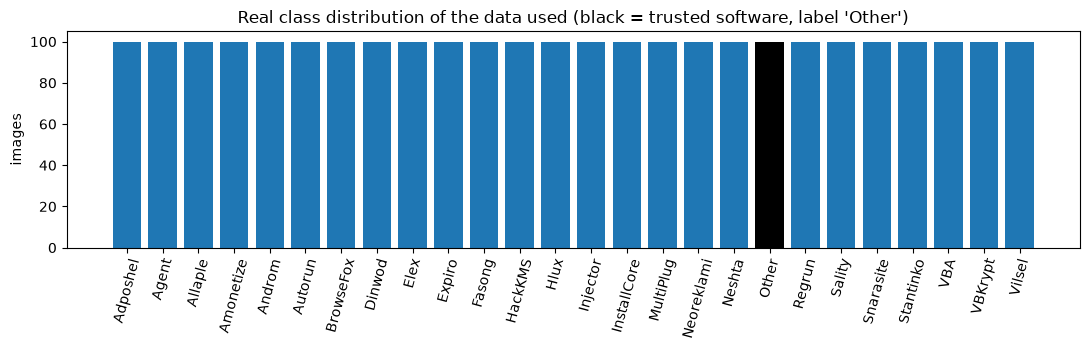

In [6]:
print("dataset shape (images, height, width, channels):", X25.shape, "(25x25 for the hybrid model) and", X32.shape, "(32x32 for LeNet)")
print("flattened feature vector for the classical baselines:", X25.reshape(len(X25), -1).shape[1], "pixel features:",
      ", ".join(f"pix_{r}_{c}" for r in range(2) for c in range(3)), "... pix_24_24")
print("original labels (folder names):", CLASSES)
counts = sel["family"].value_counts().reindex(CLASSES)
print("\nclass counts in the data used here:")
print(counts.to_string())
print("\nPaper counts for comparison: Adposhel 494, Agent 470, Allaple 478, ... trusted 1832 (full dataset; our 'Other' = trusted).")
print("\nsplit sizes per class (train/val/test):")
print(pd.DataFrame({"train": np.bincount(ytr, minlength=26), "val": np.bincount(yva, minlength=26),
                    "test": np.bincount(yte, minlength=26)}, index=CLASSES).T.to_string())

fig, ax = plt.subplots(figsize=(11, 3.6))
cols = ["black" if c == "Other" else "tab:blue" for c in CLASSES]
ax.bar(CLASSES, counts.values, color=cols); ax.set_ylabel("images"); ax.tick_params(axis="x", rotation=75)
ax.set_title("Real class distribution of the data used (black = trusted software, label 'Other')")
plt.tight_layout(); plt.show()

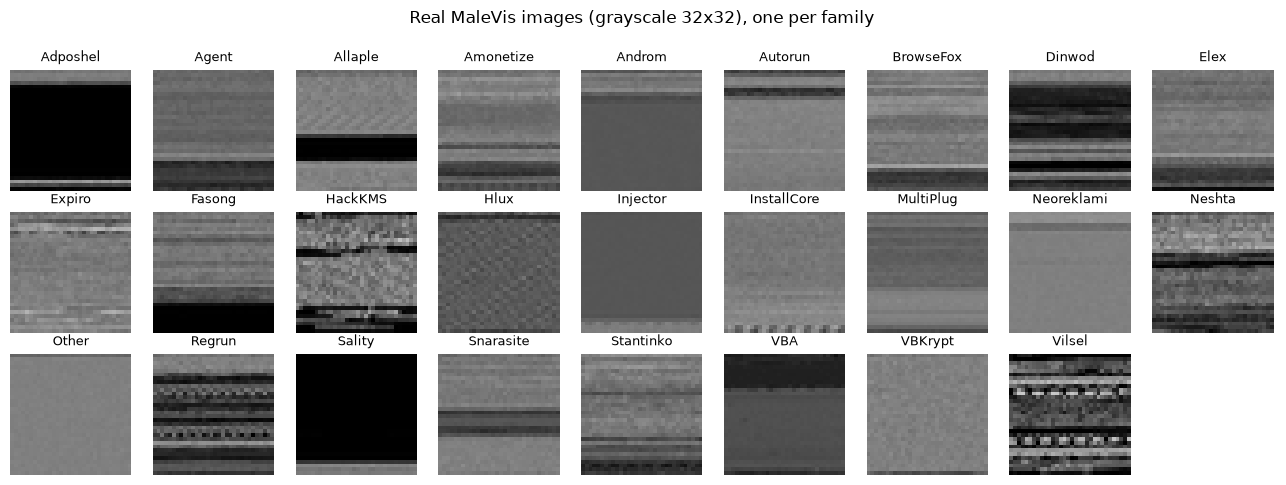

In [7]:
# one real example per family (bigger 32x32 version), taken from the training split
fig, axes = plt.subplots(3, 9, figsize=(13, 4.8))
for ax in axes.ravel(): ax.axis("off")
for k, c in enumerate(CLASSES):
    i = np.where(ytr == k)[0][0]
    axes.ravel()[k].imshow(Ltr[i, ..., 0], cmap="gray", vmin=0, vmax=1); axes.ravel()[k].set_title(c, fontsize=9)
fig.suptitle("Real MaleVis images (grayscale 32x32), one per family", y=1.0); plt.tight_layout(); plt.show()

explained variance of the two components: [0.499 0.138]


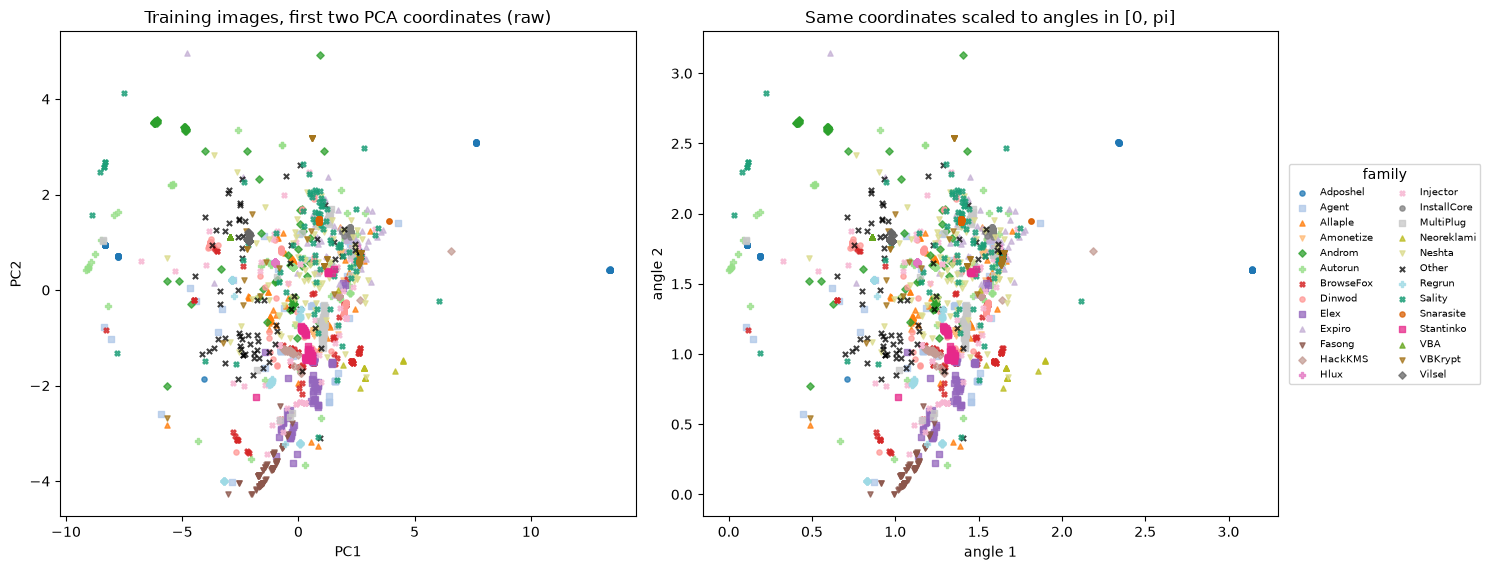

In [8]:
# 2-D scatter of REAL images coloured by ground-truth family.  PCA is fitted on the training split only.
pca2 = PCA(n_components=2, random_state=SEED).fit(Xtr.reshape(len(Xtr), -1))
Ptr, Pte = pca2.transform(Xtr.reshape(len(Xtr), -1)), pca2.transform(Xte.reshape(len(Xte), -1))
print("explained variance of the two components:", np.round(pca2.explained_variance_ratio_, 3))
palette = list(plt.cm.tab20(np.linspace(0, 1, 20))) + list(plt.cm.Dark2(np.linspace(0, 1, 6)))
markers = ["o", "s", "^", "v", "D", "P", "X"]
def scatter_families(ax, P, y, title, sub=2500):
    sel_ = np.random.default_rng(SEED).permutation(len(y))[:sub]
    for k, c in enumerate(CLASSES):
        m = sel_[y[sel_] == k]
        ax.scatter(P[m, 0], P[m, 1], s=14, color=("black" if c == "Other" else palette[k % len(palette)]),
                   marker=("x" if c == "Other" else markers[k % len(markers)]), alpha=0.75, label=c)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
scatter_families(axes[0], Ptr, ytr, "Training images, first two PCA coordinates (raw)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
# the same coordinates as rotation angles in [0, pi]: scaler fitted on the training split, test angles are clipped
sc = MinMaxScaler((0, np.pi)).fit(Ptr)
Atr = sc.transform(Ptr); Ate = np.clip(sc.transform(Pte), 0, np.pi)
scatter_families(axes[1], Atr, ytr, "Same coordinates scaled to angles in [0, pi]")
axes[1].set_xlabel("angle 1"); axes[1].set_ylabel("angle 2")
axes[1].legend(ncol=2, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5), title="family")
plt.tight_layout(); plt.show()

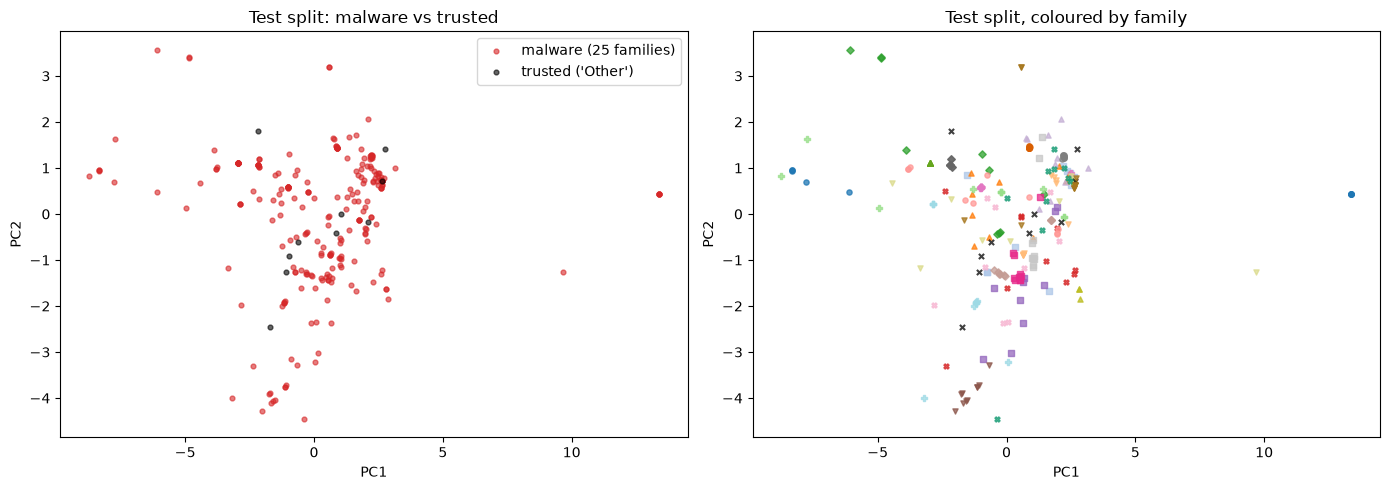

In [9]:
# the same real test images in the same PCA plane: trusted vs malware (binary view) and the whole test split by family
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
is_trusted = np.array(CLASSES)[yte] == "Other"
axes[0].scatter(Pte[~is_trusted, 0], Pte[~is_trusted, 1], s=12, c="tab:red", alpha=.6, label="malware (25 families)")
axes[0].scatter(Pte[is_trusted, 0], Pte[is_trusted, 1], s=12, c="black", alpha=.6, label="trusted ('Other')")
axes[0].set_title("Test split: malware vs trusted"); axes[0].legend(); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
scatter_families(axes[1], Pte, yte, "Test split, coloured by family", sub=len(yte))
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.tight_layout(); plt.show()

## 2. The quanvolutional layer (`QConv`)

A normal convolution slides a small window over the picture and computes a weighted sum. A **quanvolution** (Henderson et al.) replaces that sum by a small quantum circuit. Our `QConv` does this for every 2x2 window (stride 1):

1. **Encoding.** The four pixel values `x1..x4` in [0, 1] are loaded onto four qubits with rotations `RY(pi * x_i)`.
2. **Trainable circuit.** Two layers of `[RY(theta) on each qubit, then CNOT 0->1, 1->2, 2->3, 3->0]` entangle the four pixels. The angles `theta` are learned.
3. **Read-out.** The output value is the expectation of Pauli-Z on qubit 0, a number in [-1, 1], followed by ReLU as in the paper's listing.
4. **Depth = 8.** We use 8 independent trainable circuits, so the layer outputs 8 channels, like `Conv2D(8, (2, 2))` would.

Because only `RY` and `CNOT` gates are used, all amplitudes stay real and the 16 amplitudes of the 4-qubit state can be simulated *exactly* with a few tensor operations. Writing the simulation in TensorFlow means the quantum angles are trained by ordinary back-propagation (exact gradients, no shot noise), exactly like the "simulated quantum computer" of the paper. A later cell checks the layer against a Qiskit statevector simulation of the very same circuit.

In [10]:
N_Q = 4            # qubits per 2x2 patch (one qubit per pixel)
N_VAR_LAYERS = 2   # variational layers per filter (RY on every qubit + CNOT ring)
CNOT_RING = [(0, 1), (1, 2), (2, 3), (3, 0)]

def _cnot_perm(c, t, n=N_Q):
    """Permutation matrix of CNOT(control c, target t); qubit 0 = most significant bit of the basis index."""
    P = np.zeros((2 ** n, 2 ** n), dtype=np.float32)
    for i in range(2 ** n):
        bits = [(i >> (n - 1 - q)) & 1 for q in range(n)]
        if bits[c]: bits[t] ^= 1
        j = sum(b << (n - 1 - q) for q, b in enumerate(bits))
        P[j, i] = 1.0
    return P

RING_PERM = np.eye(2 ** N_Q, dtype=np.float32)
for _c, _t in CNOT_RING:
    RING_PERM = _cnot_perm(_c, _t) @ RING_PERM          # first CNOT(0,1) acts first
Z0_DIAG = np.array([1.0 - 2.0 * ((i >> (N_Q - 1)) & 1) for i in range(2 ** N_Q)], dtype=np.float32)   # <Z> on qubit 0

def ry_layer_unitary(theta):
    """theta: (F, 4) -> (F, 16, 16) real matrix of RY(theta_0) x RY(theta_1) x RY(theta_2) x RY(theta_3)."""
    c, s = tf.cos(theta / 2), tf.sin(theta / 2)
    R = tf.stack([tf.stack([c, -s], -1), tf.stack([s, c], -1)], -2)     # (F, 4, 2, 2)
    U = R[:, 0]
    for q in range(1, N_Q):
        Rq = R[:, q]
        U = tf.reshape(tf.einsum("fab,fcd->facbd", U, Rq), (tf.shape(theta)[0], U.shape[1] * 2, U.shape[2] * 2))
    return U

def filter_unitaries(theta):
    """theta: (F, L, 4) -> U (F,16,16) = prod_l [CNOT ring . RY layer l]."""
    F = theta.shape[0]
    U = tf.eye(2 ** N_Q, batch_shape=[F])
    for l in range(theta.shape[1]):
        U = tf.matmul(tf.constant(RING_PERM)[None], tf.matmul(ry_layer_unitary(theta[:, l]), U))
    return U

def encode_patches(x):
    """x: (..., 4) pixel intensities in [0,1] -> product-state amplitudes (..., 16) of RY(pi*x_i)|0>."""
    ang = np.pi * x / 2.0
    c, s = tf.cos(ang), tf.sin(ang)
    st = tf.stack([c[..., 0], s[..., 0]], -1)
    for q in range(1, N_Q):
        nxt = tf.stack([c[..., q], s[..., q]], -1)
        st = tf.reshape(st[..., :, None] * nxt[..., None, :], tf.concat([tf.shape(st)[:-1], [st.shape[-1] * 2]], 0))
    return st


@keras.saving.register_keras_serializable(package="qml")
class QConv(layers.Layer):
    """Quanvolutional layer: every 2x2 patch (stride 1) is encoded on 4 qubits (RY(pi x)), passed through a
    trainable 4-qubit circuit (one circuit per output channel) and the output channel is <Z_0>."""
    def __init__(self, filters=8, activation="relu", **kw):
        super().__init__(**kw); self.filters = filters; self.act = keras.activations.get(activation)
    def build(self, input_shape):
        self.theta = self.add_weight(shape=(self.filters, N_VAR_LAYERS, N_Q),
                                     initializer=keras.initializers.RandomUniform(-np.pi, np.pi), name="theta")
        super().build(input_shape)
    def observables(self):
        U = filter_unitaries(self.theta)                                # (F,16,16)
        return tf.einsum("fki,k,fkj->fij", U, tf.constant(Z0_DIAG), U)   # U^T Z0 U
    def call(self, x):
        p = tf.image.extract_patches(x, [1, 2, 2, 1], [1, 1, 1, 1], [1, 1, 1, 1], "VALID")   # (B,H-1,W-1,4)
        psi = encode_patches(p)                                          # (B,H-1,W-1,16)
        M = self.observables()
        out = tf.einsum("bhwi,fij,bhwj->bhwf", psi, M, psi)
        return self.act(out)
    def compute_output_shape(self, s):
        return (s[0], s[1] - 1, s[2] - 1, self.filters)

## 3. Models and metrics

* **Hybrid QCNN** (the paper's model, Listing 1): `QConv(8)` -> `Conv2D(16, 2x2, relu)` -> `Flatten` -> `Dense(32, relu)` -> `Dense(26, softmax)` on 25x25x1 pictures.
* **Classical twin**: the identical network with the quanvolutional layer replaced by `Conv2D(8, 2x2, relu)` (same input, same everything else). This is the fair classical baseline for the quantum layer.
* **LeNet-5** on 32x32x1 pictures (the paper's classical baseline).
* **Random Forest** and **SVC (RBF)** on the same 25x25 pixels as the hybrid model (flattened to 625 numbers).

Metrics are macro-averaged over the 26 classes (precision, recall, F-measure), accuracy over all test images, and AUC is the macro-average of one-vs-rest AUCs.

In [11]:
CLASS_N = len(CLASSES)
def make_hybrid(quantum=True):
    keras.utils.set_random_seed(SEED)
    inp = keras.Input((IMG_Q, IMG_Q, 1))
    x = QConv(N_FILTERS, name="qconv1")(inp) if quantum else layers.Conv2D(N_FILTERS, (2, 2), activation="relu", name="conv1")(inp)
    x = layers.Conv2D(16, (2, 2), activation="relu", name="conv_last")(x)        # last conv layer: target of the CAMs
    x = layers.Flatten()(x)
    x = layers.Dense(32, activation="relu")(x)
    z = layers.Dense(CLASS_N, name="logits")(x)
    out = layers.Softmax(name="probs")(z)
    m = keras.Model(inp, out, name="hybrid_qcnn" if quantum else "classical_twin")
    m.compile(keras.optimizers.Adam(LEARNING_RATE), "sparse_categorical_crossentropy", metrics=["accuracy"])   # CHOICE: Adam
    return m

def make_lenet():
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential([keras.Input((IMG_L, IMG_L, 1)),
        layers.Conv2D(6, 5, activation="tanh"), layers.AveragePooling2D(2),
        layers.Conv2D(16, 5, activation="tanh"), layers.AveragePooling2D(2), layers.Flatten(),
        layers.Dense(120, activation="tanh"), layers.Dense(84, activation="tanh"), layers.Dense(CLASS_N, activation="softmax")],
        name="lenet5")
    m.compile(keras.optimizers.Adam(LEARNING_RATE), "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def auc_ovr(y, scores):
    a = [roc_auc_score(y == k, scores[:, k]) for k in range(CLASS_N) if (y == k).any() and (y != k).any()]
    return float(np.mean(a))

def metrics(y, scores):
    pred = scores.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=range(CLASS_N), average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision=p, recall=r, f1=f, auc=auc_ovr(y, scores))

RUNS = {}          # (model name, epochs, batch) -> dict
def train_run(name, build, Xa, Xb, Xc, epochs, bs):
    m = build()
    t = time.time()
    h = m.fit(Xa, ytr, validation_data=(Xb, yva), epochs=epochs, batch_size=bs, shuffle=True, verbose=2)
    p_te = m.predict(Xc, batch_size=256, verbose=0)
    dt = time.time() - t                       # training + test prediction wall-clock
    val_acc = float(m.evaluate(Xb, yva, verbose=0)[1])
    RUNS[(name, epochs, bs)] = dict(model=m, hist=h.history, time_min=dt / 60, probs=p_te, val_acc=val_acc, **metrics(yte, p_te))
    r = RUNS[(name, epochs, bs)]
    print(f"==> {name} (epochs={epochs}, batch={bs}): val_acc={val_acc:.3f} test acc={r['accuracy']:.3f} P={r['precision']:.3f} "
          f"R={r['recall']:.3f} F={r['f1']:.3f} AUC={r['auc']:.3f} time={r['time_min']:.1f} min", flush=True)
    return RUNS[(name, epochs, bs)]

m0 = make_hybrid(); m0.summary()
print("quantum parameters in QConv:", int(np.prod(m0.get_layer("qconv1").theta.shape)))

Model: "hybrid_qcnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 25, 25, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ qconv1 (QConv)                  │ (None, 24, 24, 8)      │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_last (Conv2D)              │ (None, 23, 23, 16)     │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8464)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       270,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 26)             │           858 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Softmax)                 │ (None, 26)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 272,330 (1.04 MB)

 Trainable params: 272,330 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

quantum parameters in QConv: 64


### 3.1 Training the hybrid quantum-classical network

One run per (epochs, batch size) setting. A time budget (`MAX_TRAIN_MIN`) protects the full run: settings that would start after the budget is used up are skipped and reported. The best setting is selected on the **validation** split (not on the test split), and only then are its test numbers reported.

In [12]:
T_START = time.time(); SKIPPED = []
for ep, bs in CONFIGS:
    if RUNS and (time.time() - T_START) / 60 > MAX_TRAIN_MIN:
        SKIPPED.append((ep, bs)); print(f"skipping setting epochs={ep}, batch={bs}: training budget of {MAX_TRAIN_MIN} min used up"); continue
    train_run("Hybrid QCNN", make_hybrid, Xtr, Xva, Xte, ep, bs)
hyb = {k: v for k, v in RUNS.items() if k[0] == "Hybrid QCNN"}
BEST = max(hyb, key=lambda k: hyb[k]["val_acc"])
print("\nbest hybrid setting chosen on validation accuracy:", BEST[1:], "| skipped settings:", SKIPPED)

Epoch 1/5


65/65 - 38s - 583ms/step - accuracy: 0.2635 - loss: 2.8186 - val_accuracy: 0.4269 - val_loss: 2.2800


Epoch 2/5


65/65 - 22s - 338ms/step - accuracy: 0.5375 - loss: 1.7847 - val_accuracy: 0.5846 - val_loss: 1.5361


Epoch 3/5


...

65/65 - 13s - 194ms/step - accuracy: 0.7375 - loss: 1.0525 - val_accuracy: 0.7154 - val_loss: 1.0514


Epoch 5/5


65/65 - 14s - 216ms/step - accuracy: 0.7635 - loss: 0.9138 - val_accuracy: 0.7538 - val_loss: 0.9303


==> Hybrid QCNN (epochs=5, batch=32): val_acc=0.754 test acc=0.738 P=0.771 R=0.738 F=0.736 AUC=0.947 time=1.9 min



best hybrid setting chosen on validation accuracy: (5, 32) | skipped settings: []


### 3.2 Baselines on identical inputs

The classical twin (same architecture, no quantum layer) is trained for the first setting and for the selected best setting; LeNet-5 (32x32 pictures) for every setting; Random Forest and SVC use the same 25x25 pixels.

In [13]:
for ep, bs in sorted({CONFIGS[0], BEST[1:]}):
    train_run("Classical twin", lambda: make_hybrid(quantum=False), Xtr, Xva, Xte, ep, bs)
for ep, bs in CONFIGS:
    if ("Hybrid QCNN", ep, bs) in RUNS:                 # only settings that the hybrid model also ran
        train_run("LeNet-5", make_lenet, Ltr, Lva, Lte, ep, bs)

Ftr, Fva, Fte = (a.reshape(len(a), -1) for a in (Xtr, Xva, Xte))
t = time.time()
rf = RandomForestClassifier(n_estimators=RF_TREES, n_jobs=2, random_state=SEED).fit(Ftr, ytr)
rf_scores = rf.predict_proba(Fte); rf_time = (time.time() - t) / 60
t = time.time()
svc = SVC(kernel="rbf", C=10, gamma="scale", decision_function_shape="ovr", random_state=SEED).fit(Ftr, ytr)   # CHOICE: C=10
svc_scores = svc.decision_function(Fte); svc_time = (time.time() - t) / 60
BASE = {"Random Forest": dict(time_min=rf_time, **metrics(yte, rf_scores)), "SVC (RBF)": dict(time_min=svc_time, **metrics(yte, svc_scores))}
for k, v in BASE.items(): print(k, {a: round(b, 3) for a, b in v.items()})

Epoch 1/5


65/65 - 35s - 541ms/step - accuracy: 0.1813 - loss: 2.9751 - val_accuracy: 0.3000 - val_loss: 2.5404


Epoch 2/5


65/65 - 10s - 147ms/step - accuracy: 0.5034 - loss: 2.0620 - val_accuracy: 0.5731 - val_loss: 1.7103


Epoch 3/5


...

65/65 - 10s - 150ms/step - accuracy: 0.6139 - loss: 1.5742 - val_accuracy: 0.6115 - val_loss: 1.5057


Epoch 5/5


65/65 - 8s - 128ms/step - accuracy: 0.6538 - loss: 1.3856 - val_accuracy: 0.6423 - val_loss: 1.3701


==> LeNet-5 (epochs=5, batch=32): val_acc=0.642 test acc=0.615 P=0.633 R=0.615 F=0.586 AUC=0.914 time=2.5 min


Random Forest {'time_min': 0.662, 'accuracy': 0.85, 'precision': 0.873, 'recall': 0.85, 'f1': 0.857, 'auc': 0.986}
SVC (RBF) {'time_min': 0.725, 'accuracy': 0.835, 'precision': 0.845, 'recall': 0.835, 'f1': 0.835, 'auc': 0.94}


In [14]:
rows = []
for (name, ep, bs), r in RUNS.items():
    rows.append(dict(model=name, epochs=ep, batch=bs, val_acc=r["val_acc"], accuracy=r["accuracy"], precision=r["precision"],
                     recall=r["recall"], f1=r["f1"], auc=r["auc"], time_min=r["time_min"]))
for k, v in BASE.items():
    rows.append(dict(model=k, epochs=np.nan, batch=np.nan, val_acc=np.nan, **{a: v[a] for a in ("accuracy", "precision", "recall", "f1", "auc", "time_min")}))
RESULT_TABLE = pd.DataFrame(rows)
print("Test-set results of every run (compare with the paper's Table II):")
print(RESULT_TABLE.round(3).to_string(index=False))

Test-set results of every run (compare with the paper's Table II):


         model  epochs  batch  val_acc  accuracy  precision  recall    f1   auc  time_min
   Hybrid QCNN     5.0   32.0    0.754     0.738      0.771   0.738 0.736 0.947     1.893
Classical twin     5.0   32.0    0.685     0.662      0.642   0.662 0.637 0.932     1.543
       LeNet-5     5.0   32.0    0.642     0.615      0.633   0.615 0.586 0.914     2.486
 Random Forest     NaN    NaN      NaN     0.850      0.873   0.850 0.857 0.986     0.662
     SVC (RBF)     NaN    NaN      NaN     0.835      0.845   0.835 0.835 0.940     0.725


### 3.3 The paper's Figures 2 to 4: accuracy, loss and confusion matrix of the selected hybrid model

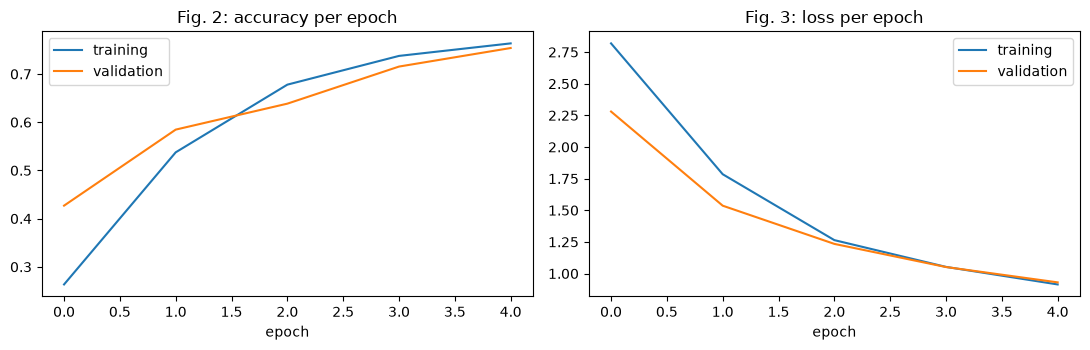

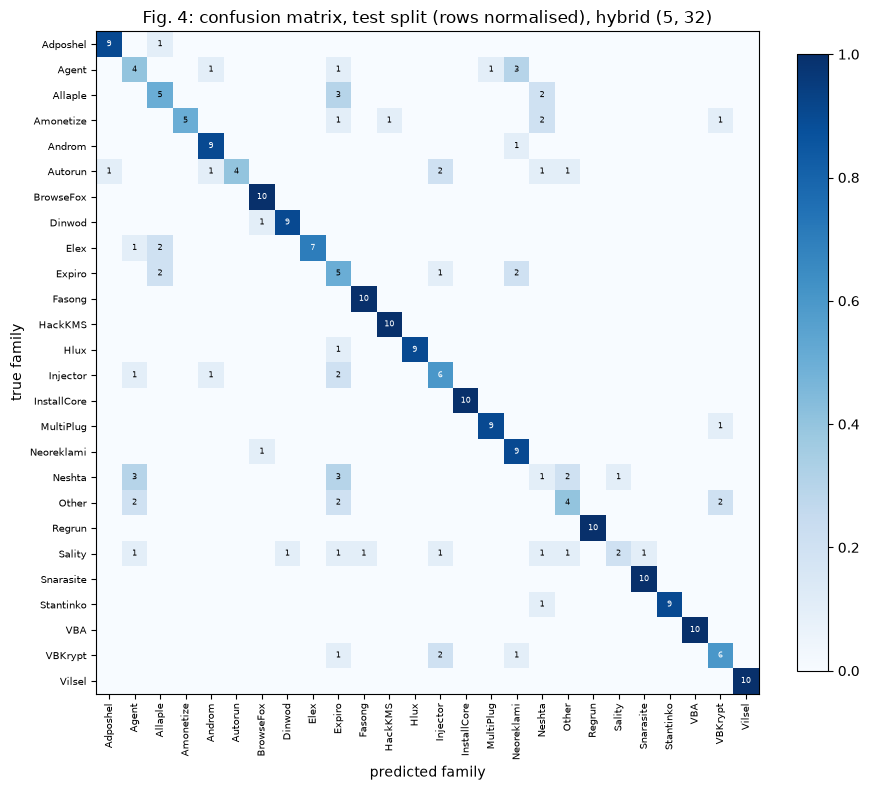

In [15]:
H = RUNS[BEST]["hist"]; best_model = RUNS[BEST]["model"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(H["accuracy"], label="training"); ax[0].plot(H["val_accuracy"], label="validation"); ax[0].set_title("Fig. 2: accuracy per epoch"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(H["loss"], label="training"); ax[1].plot(H["val_loss"], label="validation"); ax[1].set_title("Fig. 3: loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

pred_best = RUNS[BEST]["probs"].argmax(1)
cm = confusion_matrix(yte, pred_best, labels=range(CLASS_N))
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(CLASS_N)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7); ax.set_yticks(range(CLASS_N)); ax.set_yticklabels(CLASSES, fontsize=7)
for i in range(CLASS_N):
    for j in range(CLASS_N):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5.5, color="white" if cm[i, j] / cm[i].sum() > .5 else "black")
ax.set_xlabel("predicted family"); ax.set_ylabel("true family"); ax.set_title(f"Fig. 4: confusion matrix, test split (rows normalised), hybrid {BEST[1:]}")
plt.colorbar(im, fraction=0.04); plt.tight_layout(); plt.show()

In [16]:
# per-family results (paper: Sality acc .960 P .428 R .235 F .303 AUC .611; six families perfect)
pr, rc, f1, sup = precision_recall_fscore_support(yte, pred_best, labels=range(CLASS_N), zero_division=0)
P_best = RUNS[BEST]["probs"]
fam = pd.DataFrame({"family": CLASSES, "support": sup, "precision": pr, "recall": rc, "f1": f1,
                    "one-vs-rest accuracy": [((pred_best == k) == (yte == k)).mean() for k in range(CLASS_N)],
                    "AUC": [roc_auc_score(yte == k, P_best[:, k]) for k in range(CLASS_N)]})
print(fam.round(3).sort_values("f1").to_string(index=False))
PERFECT = ["Adposhel", "Fasong", "HackKMS", "Regrun", "Snarasite", "VBA"]
print("\nfamilies the paper reports as perfectly classified ->", fam[fam.family.isin(PERFECT)][["family", "precision", "recall", "f1"]].round(3).to_dict("records"))

     family  support  precision  recall    f1  one-vs-rest accuracy   AUC
     Neshta       10      0.125     0.1 0.111                 0.938 0.690
     Sality       10      0.667     0.2 0.308                 0.965 0.862
     Expiro       10      0.250     0.5 0.333                 0.923 0.918
      Agent       10      0.333     0.4 0.364                 0.946 0.839
      Other       10      0.500     0.4 0.444                 0.962 0.892
    Allaple       10      0.500     0.5 0.500                 0.962 0.893
   Injector       10      0.500     0.6 0.545                 0.962 0.823
    Autorun       10      1.000     0.4 0.571                 0.977 0.967
    VBKrypt       10      0.600     0.6 0.600                 0.969 0.926
  Amonetize       10      1.000     0.5 0.667                 0.981 0.886
 Neoreklami       10      0.562     0.9 0.692                 0.969 0.998
     Androm       10      0.750     0.9 0.818                 0.985 0.976
       Elex       10      1.000     0.


families the paper reports as perfectly classified -> [{'family': 'Adposhel', 'precision': 0.9, 'recall': 0.9, 'f1': 0.9}, {'family': 'Fasong', 'precision': 0.909, 'recall': 1.0, 'f1': 0.952}, {'family': 'HackKMS', 'precision': 0.909, 'recall': 1.0, 'f1': 0.952}, {'family': 'Regrun', 'precision': 1.0, 'recall': 1.0, 'f1': 1.0}, {'family': 'Snarasite', 'precision': 0.909, 'recall': 1.0, 'f1': 0.952}, {'family': 'VBA', 'precision': 1.0, 'recall': 1.0, 'f1': 1.0}]


## Quantum Circuit Architecture

The quanvolutional layer *is* a quantum circuit: one 4-qubit circuit per output channel, run once per 2x2 window. The next cell rebuilds filter 0 as a Qiskit `QuantumCircuit` with the trained angles of the selected hybrid model and a real 2x2 window from the test split, draws it, and prints qubit count, depth and parameter counts. The cell after it **asserts** that an exact Qiskit statevector simulation of these circuits gives the same numbers as the TensorFlow layer that was trained (all 8 filters, all windows of two real test pictures).

*Assumptions where the paper is silent:* gate set (RY, CNOT), number of variational layers (2), CNOT ring, read-out qubit (qubit 0), pixel encoding (`RY(pi x)`), and `depth=8` read as 8 channels (see the table at the top).

real window (pixels x1..x4 from test image 0): [0.596 0.576 0.576 0.525]
qubits: 4 | depth: 12 | gate counts: {'ry': 12, 'cx': 8, 'barrier': 3, 'measure': 1}
trainable parameters per filter circuit: 8 | in the whole QConv layer (8 filters): 64


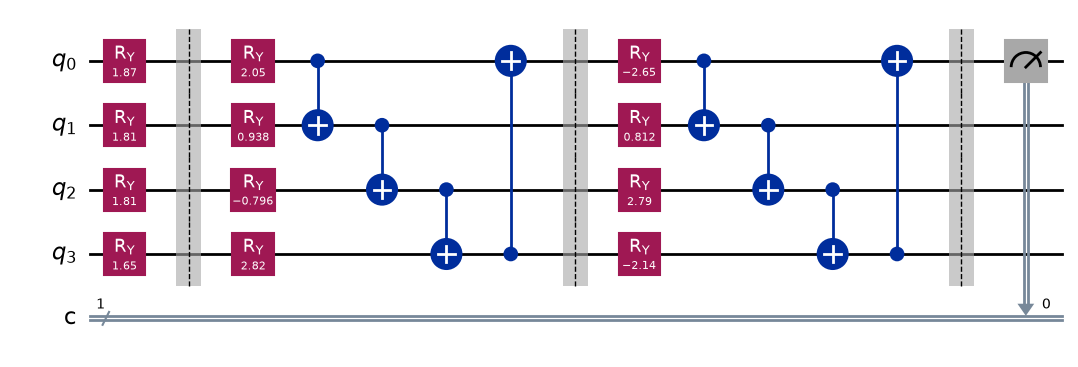

In [17]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
CNOT_PAIRS = [(0, 1), (1, 2), (2, 3), (3, 0)]
def patch_circuit(patch4, theta_f, measure=False):
    # theta_f: (layers, 4) trained angles of one filter.  Qubit i holds pixel i of the 2x2 window (row-major).
    qc = QuantumCircuit(4, 1 if measure else 0)
    for i in range(4): qc.ry(float(np.pi * patch4[i]), i)              # encoding (data, not trainable)
    qc.barrier()
    for l in range(theta_f.shape[0]):
        for q in range(4): qc.ry(float(theta_f[l, q]), q)              # trainable rotations
        for c, t in CNOT_PAIRS: qc.cx(c, t)                            # entanglement
        qc.barrier()
    if measure: qc.measure(0, 0)                                       # read-out of qubit 0 (Z expectation = 1 - 2 P(1))
    return qc

qlayer = best_model.get_layer("qconv1"); theta_trained = qlayer.theta.numpy()          # (8 filters, 2 layers, 4)
img = Xte[0, :, :, 0]; window = img[10:12, 10:12].reshape(-1)
qc_draw = patch_circuit(window, theta_trained[0], measure=True)
print("real window (pixels x1..x4 from test image 0):", np.round(window, 3))
print("qubits:", qc_draw.num_qubits, "| depth:", qc_draw.depth(), "| gate counts:", dict(qc_draw.count_ops()))
print("trainable parameters per filter circuit:", theta_trained[0].size, "| in the whole QConv layer (8 filters):", theta_trained.size)
qc_draw.draw("mpl", fold=-1)

In [18]:
# Equivalence check: exact Qiskit statevector simulation of the circuit == the TensorFlow layer used in training
lin = QConv(N_FILTERS, activation=None); lin.build((None, IMG_Q, IMG_Q, 1)); lin.theta.assign(theta_trained)
imgs = Xte[:2]
tf_out = lin(imgs).numpy()                                              # (2, 24, 24, 8) pre-activation <Z0>
H0 = SparsePauliOp("IIIZ")                                              # Qiskit is little-endian: qubit 0 is the right-most letter
max_err, n_checked = 0.0, 0
for b in range(2):
    for i in range(IMG_Q - 1):
        for j in range(IMG_Q - 1):
            w4 = imgs[b, i:i + 2, j:j + 2, 0].reshape(-1)
            for f in range(N_FILTERS):
                e = Statevector(patch_circuit(w4, theta_trained[f])).expectation_value(H0).real
                max_err = max(max_err, abs(e - tf_out[b, i, j, f])); n_checked += 1
print(f"{n_checked} circuit evaluations compared; max |Qiskit - TensorFlow layer| = {max_err:.2e}")
assert max_err < 1e-4, "the TensorFlow layer does not match the Qiskit circuit"
print("OK: the simulator used for training is the circuit drawn above.")
# also: the layer's output after ReLU is what the network passes on
assert np.allclose(np.maximum(tf_out, 0), qlayer(imgs).numpy(), atol=1e-5)

9216 circuit evaluations compared; max |Qiskit - TensorFlow layer| = 3.44e-07
OK: the simulator used for training is the circuit drawn above.


## 4. Explainability: Grad-CAM++ and Score-CAM

Both methods build a heat-map from the feature maps `A_k` of the last convolutional layer (`conv_last`, 16 maps of size 23x23) of the network, for one chosen class `c`:

* **Grad-CAM++** weights each map by the *positive gradients* of the class score with respect to that map, with a closed-form second-order correction (Chattopadhay et al. 2018): `w_k = sum_ij alpha_ij^k relu(dY_c/dA_ij^k)`.
* **Score-CAM** (Wang et al. 2020) uses no gradients: every map is up-sampled, scaled to [0, 1] and used as a mask on the input picture; the *increase in the class probability* caused by each mask, passed through a softmax, becomes the weight `w_k`.

The final map is `ReLU(sum_k w_k A_k)`, up-sampled to 25x25 and scaled to [0, 1]. Colours follow the paper: yellow = important, blue = ignored. We then go beyond looking at two examples: the agreement of the two methods and a deletion test are computed over many test pictures.

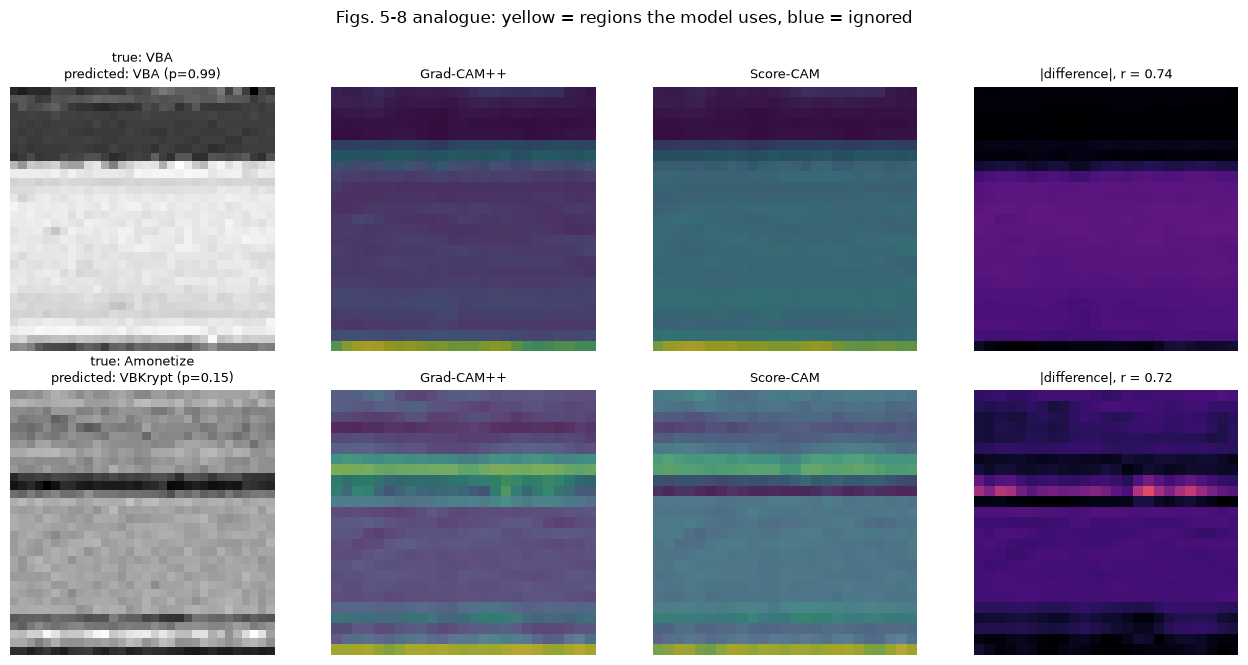

In [19]:
cam_model = keras.Model(best_model.inputs, [best_model.get_layer("conv_last").output, best_model.get_layer("logits").output])
def norm01(a):
    a = a - a.min(); return a / (a.max() + 1e-8)
def to_img(cam):
    return norm01(tf.image.resize(cam[None, ..., None], (IMG_Q, IMG_Q), method="bilinear").numpy()[0, ..., 0])

def gradcam_pp(x, cls):
    x = tf.convert_to_tensor(x[None])
    with tf.GradientTape() as tape:
        A, z = cam_model(x); s = z[:, cls]
    g = tape.gradient(s, A)                                              # d(class logit)/dA
    g2, g3 = g ** 2, g ** 3
    alpha = tf.math.divide_no_nan(g2, 2 * g2 + tf.reduce_sum(A, axis=(1, 2), keepdims=True) * g3)
    w = tf.reduce_sum(alpha * tf.nn.relu(g), axis=(1, 2))                # (1, K)
    cam = tf.nn.relu(tf.reduce_sum(w[:, None, None, :] * A, axis=-1))[0]
    return to_img(cam.numpy())

def score_cam(x, cls):
    A, _ = cam_model(tf.convert_to_tensor(x[None]))
    A = A[0]                                                             # (h, w, K)
    up = tf.image.resize(A, (IMG_Q, IMG_Q), method="bilinear").numpy()    # (25, 25, K)
    masks = np.stack([norm01(up[..., k]) for k in range(up.shape[-1])])[..., None].astype("float32")
    probs = best_model(x[None] * masks, training=False).numpy()[:, cls]
    base = best_model(np.zeros((1, IMG_Q, IMG_Q, 1), "float32"), training=False).numpy()[0, cls]
    w = tf.nn.softmax(probs - base).numpy()                              # channel-wise increase in confidence
    cam = np.maximum((A.numpy() * w[None, None, :]).sum(-1), 0)
    return to_img(cam)

def overlay(ax, x, cam, title):
    ax.imshow(x[..., 0], cmap="gray", vmin=0, vmax=1); ax.imshow(cam, cmap="viridis", alpha=0.6, vmin=0, vmax=1)
    ax.set_title(title, fontsize=9); ax.axis("off")

probs_best = RUNS[BEST]["probs"]
vba = CLASSES.index("VBA")
iA = next((i for i in range(len(yte)) if yte[i] == vba and pred_best[i] == vba), int(np.argmax(probs_best.max(1) * (pred_best == yte))))              # a correctly classified VBA sample (as in the paper's Figs. 5-6)
wrong = np.where(pred_best != yte)[0]
iB = wrong[np.argmin(probs_best[wrong].max(1))] if len(wrong) else int(np.argmin(probs_best.max(1)))   # an uncertain / misclassified sample (as in Figs. 7-8)
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for r, i in enumerate((iA, iB)):
    c = int(pred_best[i]); gc, sc_ = gradcam_pp(Xte[i], c), score_cam(Xte[i], c)
    axes[r, 0].imshow(Lte[i, ..., 0], cmap="gray"); axes[r, 0].axis("off")
    axes[r, 0].set_title(f"true: {CLASSES[yte[i]]}\npredicted: {CLASSES[c]} (p={probs_best[i, c]:.2f})", fontsize=9)
    overlay(axes[r, 1], Xte[i], gc, "Grad-CAM++"); overlay(axes[r, 2], Xte[i], sc_, "Score-CAM")
    axes[r, 3].imshow(np.abs(gc - sc_), cmap="magma", vmin=0, vmax=1); axes[r, 3].set_title(f"|difference|, r = {pearsonr(gc.ravel(), sc_.ravel())[0]:.2f}", fontsize=9); axes[r, 3].axis("off")
fig.suptitle("Figs. 5-8 analogue: yellow = regions the model uses, blue = ignored", y=1.0); plt.tight_layout(); plt.show()

In [20]:
# Quantitative check over many test pictures (explaining the predicted class)
sel_cam = np.random.default_rng(SEED).choice(len(yte), size=min(N_CAM, len(yte)), replace=False)
GC, SC = [], []
t = time.time()
for i in sel_cam:
    c = int(pred_best[i]); GC.append(gradcam_pp(Xte[i], c)); SC.append(score_cam(Xte[i], c))
GC, SC = np.stack(GC), np.stack(SC)
print(f"{len(sel_cam)} pictures explained in {time.time()-t:.0f}s")

def topk_mask(m, frac=0.25):
    k = int(frac * m.size); thr = np.sort(m.ravel())[-k]; return m >= thr
def iou(a, b): return (a & b).sum() / max((a | b).sum(), 1)
pear = np.array([pearsonr(GC[n].ravel(), SC[n].ravel())[0] if GC[n].std() > 0 and SC[n].std() > 0 else np.nan for n in range(len(GC))])
iou_same = np.array([iou(topk_mask(GC[n]), topk_mask(SC[n])) for n in range(len(GC))])
iou_shuf = np.array([iou(topk_mask(GC[n]), topk_mask(SC[(n + 1) % len(SC)])) for n in range(len(GC))])   # control: other picture's map
print(f"Pearson r between Grad-CAM++ and Score-CAM (same picture): mean {np.nanmean(pear):.2f}, median {np.nanmedian(pear):.2f}")
print(f"IoU of the top-25% pixels: same picture {iou_same.mean():.2f}  | control (maps of different pictures) {iou_shuf.mean():.2f}  | random-mask chance ~0.14")

# deletion test: replace the 20% most 'important' pixels by the image mean and see how much the predicted-class probability falls
rnd = np.random.default_rng(SEED); drops = {"Grad-CAM++": [], "Score-CAM": [], "random pixels": []}
for n, i in enumerate(sel_cam):
    c = int(pred_best[i]); p0 = probs_best[i, c]; x = Xte[i]
    variants = {}
    for name, cam in (("Grad-CAM++", GC[n]), ("Score-CAM", SC[n])):
        xm = x.copy(); xm[topk_mask(cam, 0.20)] = x.mean(); variants[name] = xm[None]
    xr = np.repeat(x[None], 5, 0)
    for r_ in range(5):
        xr[r_][np.unravel_index(rnd.choice(IMG_Q * IMG_Q, int(0.2 * IMG_Q * IMG_Q), replace=False), (IMG_Q, IMG_Q))] = x.mean()
    pm = {k: best_model.predict(v, verbose=0)[0, c] for k, v in variants.items()}
    pm["random pixels"] = best_model.predict(xr, verbose=0)[:, c].mean()
    for k in drops: drops[k].append(p0 - pm[k])
print("\nDeletion test, mean drop of the predicted-class probability after masking 20% of the pixels:")
for k, v in drops.items(): print(f"  {k:14s}: {np.mean(v):.3f}")
DELETION = {k: float(np.mean(v)) for k, v in drops.items()}

30 pictures explained in 156s


Pearson r between Grad-CAM++ and Score-CAM (same picture): mean 0.75, median 0.83
IoU of the top-25% pixels: same picture 0.58  | control (maps of different pictures) 0.18  | random-mask chance ~0.14



Deletion test, mean drop of the predicted-class probability after masking 20% of the pixels:
  Grad-CAM++    : 0.386
  Score-CAM     : 0.298
  random pixels : 0.116


### 4.1 Permutation importance on the quantum model and on the classical models

The paper explains only the quantum model, with image heat-maps. To see whether the *quantum* model looks at different places than *classical* models trained on the same 25x25 pixels, we add a model-agnostic method: **grouped permutation importance**. The picture is cut into 5x5 blocks of 5x5 pixels; for one block at a time, that block is shuffled between test pictures and the **fall in test accuracy** is the importance of the block (repeated several times). The same procedure is applied to the hybrid network, the classical twin, the Random Forest and the SVC. (`shap` is not installed in the tested environment, so scikit-learn-style permutation importance is used; scikit-learn's own function works on single columns, so the grouped version is written out here.)

Hybrid QCNN     baseline accuracy on 260 test pictures = 0.738, max block importance = 0.044 (153s)


Classical twin  baseline accuracy on 260 test pictures = 0.662, max block importance = 0.037 (114s)


Random Forest   baseline accuracy on 260 test pictures = 0.850, max block importance = 0.017 (65s)


SVC (RBF)       baseline accuracy on 260 test pictures = 0.831, max block importance = 0.046 (224s)


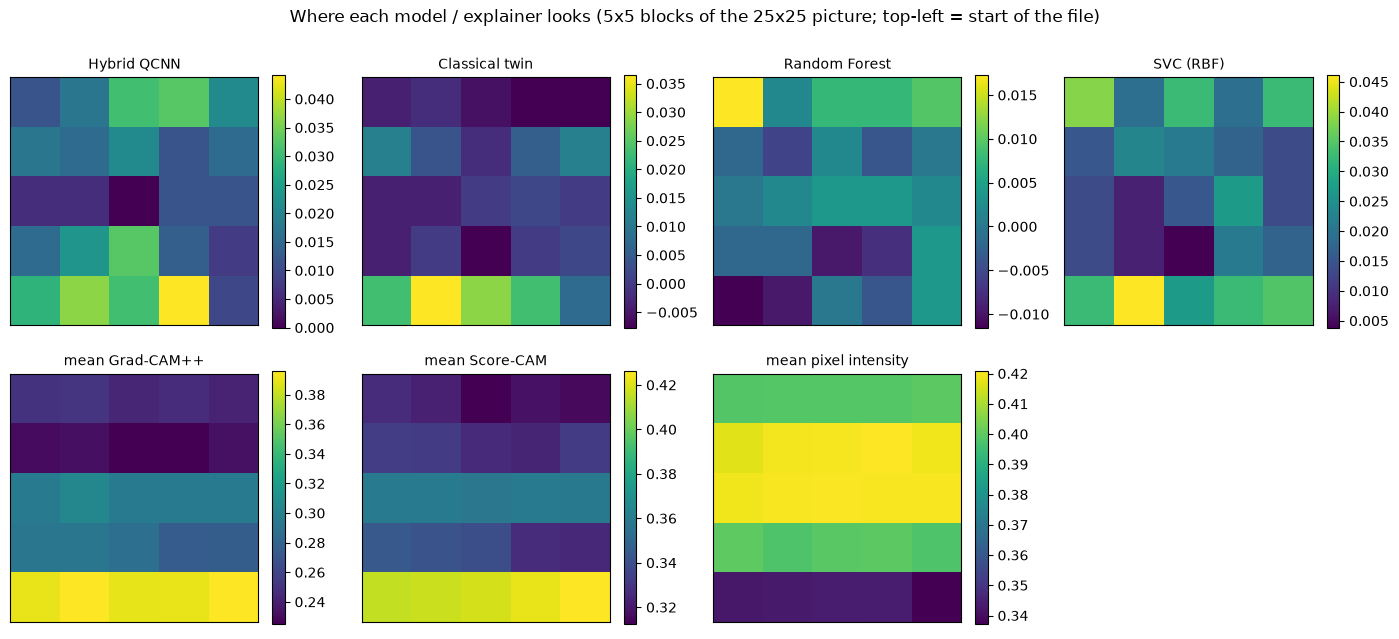

Spearman rank correlation between the 25-block maps:
                      Hybrid QCNN  Classical twin  Random Forest  SVC (RBF)  mean Grad-CAM++  mean Score-CAM  mean pixel intensity
Hybrid QCNN                  1.00            0.08          -0.33       0.29             0.01           -0.06                 -0.54
Classical twin               0.08            1.00          -0.47       0.31             0.33            0.55                 -0.26
Random Forest               -0.33           -0.47           1.00       0.17            -0.18           -0.39                  0.08
SVC (RBF)                    0.29            0.31           0.17       1.00             0.15            0.06                 -0.54
mean Grad-CAM++              0.01            0.33          -0.18       0.15             1.00            0.85                 -0.45
mean Score-CAM              -0.06            0.55          -0.39       0.06             0.85            1.00                 -0.24
mean pixel intensity        -0

In [21]:
pi_idx = np.random.default_rng(SEED + 1).choice(len(yte), size=min(PI_N, len(yte)), replace=False)
twin_key = max([k for k in RUNS if k[0] == "Classical twin"], key=lambda k: RUNS[k]["val_acc"])
twin_model = RUNS[twin_key]["model"]
predictors = {"Hybrid QCNN": lambda X: best_model.predict(X, batch_size=256, verbose=0).argmax(1),
              "Classical twin": lambda X: twin_model.predict(X, batch_size=256, verbose=0).argmax(1),
              "Random Forest": lambda X: rf.predict(X.reshape(len(X), -1)),
              "SVC (RBF)": lambda X: svc.predict(X.reshape(len(X), -1))}
def grouped_pi(pred, X, y, repeats, b=5, seed=SEED):
    r = np.random.default_rng(seed); base = accuracy_score(y, pred(X)); imp = np.zeros((IMG_Q // b, IMG_Q // b))
    for bi in range(IMG_Q // b):
        for bj in range(IMG_Q // b):
            for _ in range(repeats):
                Xp = X.copy(); perm = r.permutation(len(X))
                Xp[:, bi*b:(bi+1)*b, bj*b:(bj+1)*b, :] = X[perm][:, bi*b:(bi+1)*b, bj*b:(bj+1)*b, :]
                imp[bi, bj] += base - accuracy_score(y, pred(Xp))
    return imp / repeats, base
PI = {}
for name, fn in predictors.items():
    t = time.time(); PI[name], base_acc = grouped_pi(fn, Xte[pi_idx], yte[pi_idx], PI_REPEATS)
    print(f"{name:15s} baseline accuracy on {len(pi_idx)} test pictures = {base_acc:.3f}, max block importance = {PI[name].max():.3f} ({time.time()-t:.0f}s)")

blk = lambda m: m.reshape(5, 5, 5, 5).mean(axis=(1, 3))
MAPS = dict(PI); MAPS["mean Grad-CAM++"] = blk(GC.mean(0)); MAPS["mean Score-CAM"] = blk(SC.mean(0)); MAPS["mean pixel intensity"] = blk(Xte[pi_idx][..., 0].mean(0))
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
for ax, (k, v) in zip(axes.ravel(), MAPS.items()):
    im = ax.imshow(v, cmap="viridis"); ax.set_title(k, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, fraction=.046)
for ax in axes.ravel()[len(MAPS):]: ax.axis("off")
fig.suptitle("Where each model / explainer looks (5x5 blocks of the 25x25 picture; top-left = start of the file)", y=1.0); plt.tight_layout(); plt.show()
names = list(MAPS); S = np.array([[spearmanr(MAPS[a].ravel(), MAPS[b].ravel())[0] for b in names] for a in names])
print("Spearman rank correlation between the 25-block maps:"); print(pd.DataFrame(S, index=names, columns=names).round(2).to_string())

## 5. Side by side with the paper

Verdict rule: a number is "reproduced" when it lies within 0.02 of the paper's value (the paper's own rounding is 0.001), "exceeded" or "not reached" otherwise; qualitative claims get a stated rule. Differences must be read together with the deviations listed at the top: a different (re-implemented) quantum layer, our own training details, and, in the fast run, a small data subset and 5 epochs instead of the paper's budgets.

In [22]:
PAPER = dict(accuracy=0.850, precision=0.892, recall=0.830, f1=0.860, auc=0.974)
bh = RUNS[BEST]; rows = []
def verdict(p, o, tol=0.02):
    if abs(o - p) <= tol: return "reproduced"
    return f"exceeded (+{o-p:.3f})" if o > p else f"not reached ({o-p:+.3f})"
for k, nm in (("accuracy", "accuracy"), ("precision", "precision (macro)"), ("recall", "recall (macro)"), ("f1", "F-measure (macro)"), ("auc", "AUC (macro OvR)")):
    rows.append((f"Best hybrid QCNN {nm}", PAPER[k], round(bh[k], 3), verdict(PAPER[k], bh[k])))

lenets = {k: v for k, v in RUNS.items() if k[0] == "LeNet-5"}
best_len = max(lenets.values(), key=lambda r: r["accuracy"]) if lenets else None
if best_len:
    rows.append(("Best LeNet accuracy (paper 0.698; worst 0.128)", 0.698, round(best_len["accuracy"], 3), verdict(0.698, best_len["accuracy"])))
    worst_h = min(v["accuracy"] for v in hyb.values())
    rows.append(("Hybrid better than LeNet (best hybrid acc > best LeNet acc)", "yes", f"hybrid {bh['accuracy']:.3f} vs LeNet {best_len['accuracy']:.3f}",
                 "reproduced" if bh["accuracy"] > best_len["accuracy"] else "not reached"))
    rows.append(("LeNet worse than the worst hybrid run (best LeNet < worst hybrid)", "yes", f"best LeNet {best_len['accuracy']:.3f} vs worst hybrid {worst_h:.3f}",
                 "reproduced" if best_len["accuracy"] < worst_h else "not reached"))
    same = [(RUNS[("Hybrid QCNN",) + c]["time_min"], RUNS[("LeNet-5",) + c]["time_min"]) for c in CONFIGS if ("LeNet-5",) + c in RUNS and ("Hybrid QCNN",) + c in RUNS]
    ratio = np.mean([a / b for a, b in same])
    rows.append(("Hybrid training much slower than LeNet", ">100x (11:55:10 vs 0:00:33)", f"{ratio:.1f}x", "reproduced (direction)" if ratio > 5 else "not reached"))
tw = RUNS[twin_key]; hb_same = RUNS[("Hybrid QCNN",) + twin_key[1:]]
rows.append(("(extra) quantum layer vs classical twin, same setting, accuracy", "n/a", f"hybrid {hb_same['accuracy']:.3f} vs twin {tw['accuracy']:.3f}", "cannot be checked (not in paper)"))

if len(hyb) >= 3 and ("Hybrid QCNN", 10, 32) in RUNS:
    a = lambda e, b: RUNS[("Hybrid QCNN", e, b)]["accuracy"] if ("Hybrid QCNN", e, b) in RUNS else None
    ok_b = a(10, 64) is not None and a(10, 64) < a(10, 32)
    ok_e = a(30, 32) is not None and a(30, 32) < a(10, 32)
    rows.append(("Larger batch lowers hybrid accuracy ((10,64) < (10,32))", "0.771 < 0.850", f"{a(10,64)} vs {a(10,32)}", "reproduced" if ok_b else "not reached"))
    rows.append(("More epochs lower hybrid accuracy ((30,32) < (10,32))", "0.819 < 0.850", f"{a(30,32)} vs {a(10,32)}", "reproduced" if ok_e else "not reached"))
else:
    rows.append(("Larger batch / more epochs lower hybrid accuracy", "Table II", "only one setting trained", "cannot be checked (fast run)"))

famF = fam.set_index("family")
sal = famF.loc["Sality"]; rank_sal = int(famF["f1"].rank().loc["Sality"])
rows.append(("Sality hard (paper P .428, R .235, F .303, acc .960, AUC .611)", "F=0.303", f"P {sal.precision:.3f} R {sal.recall:.3f} F {sal.f1:.3f} acc {sal['one-vs-rest accuracy']:.3f} AUC {sal.AUC:.3f} (F rank {rank_sal}/26 from lowest)",
             "reproduced (among the 5 worst families)" if rank_sal <= 5 else f"not reached (Sality F rank {rank_sal}/26 from lowest)"))
rank_ot = int(famF["f1"].rank().loc["Other"])
rows.append(("Trusted samples are hard", "qualitative", f"F={famF.loc['Other','f1']:.3f} (rank {rank_ot}/26 from lowest)", "reproduced (among the 5 worst)" if rank_ot <= 5 else f"not reached (rank {rank_ot}/26)"))
perf = famF.loc[PERFECT, "f1"]
rows.append(("Six families classified perfectly (P=R=F=1.0)", "6 of 6 at 1.0", f"F: {', '.join(f'{k} {v:.2f}' for k, v in perf.items())}",
             "reproduced" if (perf >= 0.98).all() else f"not reached ({int((perf >= 0.98).sum())} of 6 with F >= 0.98)"))
rows.append(("Grad-CAM++ and Score-CAM highlight the same areas", "visual, 2 samples", f"mean Pearson r {np.nanmean(pear):.2f}; top-25% IoU {iou_same.mean():.2f} vs control {iou_shuf.mean():.2f}",
             "reproduced" if (np.nanmean(pear) >= 0.5 and iou_same.mean() > iou_shuf.mean() + 0.1) else "not reached"))
rows.append(("Highlighted areas are what the model uses (deletion test, added)", "not in paper", f"drop Grad-CAM++ {DELETION['Grad-CAM++']:.3f}, Score-CAM {DELETION['Score-CAM']:.3f}, random {DELETION['random pixels']:.3f}",
             "cannot be checked (not in paper); explanation faithful" if min(DELETION["Grad-CAM++"], DELETION["Score-CAM"]) > DELETION["random pixels"] else "cannot be checked (not in paper); explanation NOT more faithful than random"))
COMPARISON = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 140, "display.width", 250)
print(COMPARISON.to_string(index=False))
print("\nRun mode:", "FAST_MODE (subset, reduced budgets)" if FAST_MODE else "full", "| settings run:", [k[1:] for k in hyb], "| skipped:", SKIPPED)

                                                            claim                       paper                                                                      this notebook                                                verdict
                                        Best hybrid QCNN accuracy                        0.85                                                                              0.738                                   not reached (-0.112)
                               Best hybrid QCNN precision (macro)                       0.892                                                                              0.771                                   not reached (-0.121)
                                  Best hybrid QCNN recall (macro)                        0.83                                                                              0.738                                   not reached (-0.092)
                               Best hybrid QCNN F-measure (macro)       

## 6. Reading the paper critically

*Numbers below refer to the stored fast run (2,600 images, 260 test pictures = 10 per family, 5 epochs, one seed).*

**What we find.**

* **Accuracy.** The hybrid network reaches test accuracy 0.738 (macro precision 0.771, recall 0.738, F 0.736, AUC 0.947), below the paper's 0.850 / 0.892 / 0.830 / 0.860 / 0.974, as expected from 1/5 of the data and 5 epochs; it was still improving when training stopped (validation accuracy rose every epoch). The paper's headline therefore is **not reached here**, and the fast run cannot say whether the full run would reach it.
* **Quantum layer vs classical twin.** With the identical architecture, the quanvolutional layer scored 0.738 against 0.662 for a classical `Conv2D(8, 2x2)` layer. This is a gain of 7.6 points, but with 260 test pictures the standard error of one accuracy is about 2.7 points, there is a single seed, and the two models have different numbers of trainable weights in the first layer (64 vs 40), so this is *not* evidence of a quantum advantage. The paper never trains this twin; it only compares with LeNet, which says nothing about the quantum layer.
* **Plain classical models are strong.** A Random Forest on the same 625 pixels scores 0.850 accuracy and AUC 0.986, and an RBF-SVC 0.835, both above every neural network trained here and as high as the paper's best hybrid accuracy, in well under a minute. A study that wants to show that a quantum model "is promising" has to include such baselines.
* **LeNet comparison.** The paper's LeNet reached 0.128 to 0.698. Our LeNet-5 (tanh, Adam, pixels scaled to [0, 1]) reaches 0.615 after 5 epochs and was also still improving. A LeNet at 0.128 (almost chance for 26 classes) looks like an untrained or badly scaled baseline, so "hybrid better than LeNet" is a weak claim; here the ordering hybrid > LeNet holds, but only at this tiny budget.
* **Training time.** The paper reports hours to days for the hybrid model and seconds to minutes for LeNet. Our exact, vectorised statevector layer is not slower than LeNet in this run (wall-clock times were also disturbed by other jobs on the shared CPU), so this claim is **not reproduced**; it depends entirely on how the quantum layer is simulated.
* **Hard and easy families.** Sality is among the hardest families (F 0.308, rank 2 of 26 from the bottom; the paper: F 0.303), and trusted software ("Other") also ranks among the five hardest, as in the paper. Only two of the six families the paper calls perfect (Regrun, VBA) are perfect here; the others have F between 0.90 and 0.95 with just 10 test pictures each (one error changes F by about 0.05).
* **Explanations.** Grad-CAM++ and Score-CAM agree on the same pictures (mean Pearson r 0.75, overlap of the 25% most important pixels 0.58 against 0.18 for maps of different pictures), supporting the paper's visual claim. Masking the 20% most important pixels lowers the predicted-class probability by 0.39 (Grad-CAM++) and 0.30 (Score-CAM) against 0.12 for random pixels, so the highlighted areas are what the model uses. The paper only shows two pictures and no such test.
* **Explanations differ from permutation importance.** The block maps from permutation importance on the hybrid network are almost uncorrelated with the mean Grad-CAM++ / Score-CAM maps (Spearman about 0), and the Random Forest, the SVC and the networks put importance on different blocks. A heat-map of one picture and the loss of accuracy when a region is shuffled across pictures answer different questions, and "the model looks here" is not the same for every model family.

**Limits of the paper and of this reproduction.**

1. Images of 25x25 pixels throw away most of the byte structure of an executable; the same dataset with larger images and classical CNNs is known to be much more accurate than any number here.
2. The paper's quantum layer is described in one line of code (`QConv(filter_size=2, depth=8)`); circuit, simulator, observables and parameter count are undisclosed, so every "reproduction" is a re-implementation (see the table at the top). Our simulation is exact and noise-free; real hardware would add shot noise and gate errors.
3. Which of Table I's rows belongs to which (epochs, batch) setting, the metric averaging, the optimiser, and whether the best run was picked on test data are not stated. We select on validation data.
4. One seed, one split, 10 test pictures per family in this fast run: all per-family and architecture-comparison statements are anecdotal.
5. MaleVis images come from malware that is mostly packed or obfuscated; a picture classifier can pick up packer or compiler artefacts rather than malicious behaviour.


## 7. Exercises

1. **Quantum layer ablation.** Replace the `RY`/`CNOT` circuit by one with `RZ` and `RX` gates (the amplitudes become complex, so use `tf.complex64`). Does the accuracy change compared with the classical twin?
2. **What does "depth" mean?** Re-read the `QConv(depth=8)` line of Listing 1. Implement the alternative reading (8 variational *layers* and four read-out channels `<Z_1>..<Z_4>`) and compare.
3. **Fair budget.** Train the classical twin and the hybrid model with the same number of epochs and several seeds; report mean and standard deviation of the test accuracy. How large is the seed noise compared with the difference between the models?
4. **More explanation methods.** Add Grad-CAM (without "++") and Eigen-CAM, and compute their agreement with Score-CAM. Do the deletion-test conclusions change?
5. **Image size.** The paper used 25x25 because of simulation cost. Retrain on 16x16 and 32x32 pictures (the cache already holds 32x32) and plot accuracy against image size for the hybrid and the classical twin.